# 03 · Inventory and supply chain

How much stock is there, and do the stock, transfer and purchase tables agree with sales?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

lines = load_lines()
years = list(range(2019, 2027))
cogs = (lines[lines["FY"].isin(years)].assign(cogs=lambda d: d["net_line_EGP"] - d["margin_EGP"])
        .groupby("FY")["cogs"].sum())
units_sold = lines[lines["FY"].isin(years)].groupby("FY")["quantity"].sum()

## 1. Stock on hand

In [2]:
stock = read("monthly_stock.csv")
stock["date"] = pd.to_datetime(stock["year_month"] + "-01")
stock["FY"] = fiscal_year(stock["date"])

# value at the end of each fiscal year (September)
year_end = stock[stock["date"].dt.month == 9].pivot_table(index="FY", columns="stock_location_type",
                                                          values="closing_stock_value_EGP", aggfunc="sum")
year_end["total"] = year_end.sum(axis=1)
year_end["months_of_cover"] = year_end["total"] / (cogs / 12)
year_end.round(1)

stock_location_type,Branch,Warehouse,total,months_of_cover
FY,,,,
2019,10270610.6,45389109.4,55659720.0,56.6
2020,11199415.7,52045784.1,63245199.8,50.0
2021,12786989.2,55852133.6,68639122.8,43.1
2022,16819677.5,79952251.8,96771929.3,40.5
2023,25449100.5,113955354.9,139404455.4,36.6
2024,37011820.4,175588753.6,212600574.0,31.6
2025,51826902.8,233990285.7,285817188.5,26.3
2026,63173576.0,318703966.0,381877542.0,25.7


In [3]:
end = stock[stock["year_month"] == "2026-09"]
print("Stock value:", millions(end["closing_stock_value_EGP"].sum()))
print(f"Units: {end['closing_units'].sum():,}")
print(f"In warehouses: {end[end['stock_location_type'] == 'Warehouse']['closing_stock_value_EGP'].sum() / end['closing_stock_value_EGP'].sum():.0%}")

Stock value: 381.9M
Units: 1,874,671
In warehouses: 83%


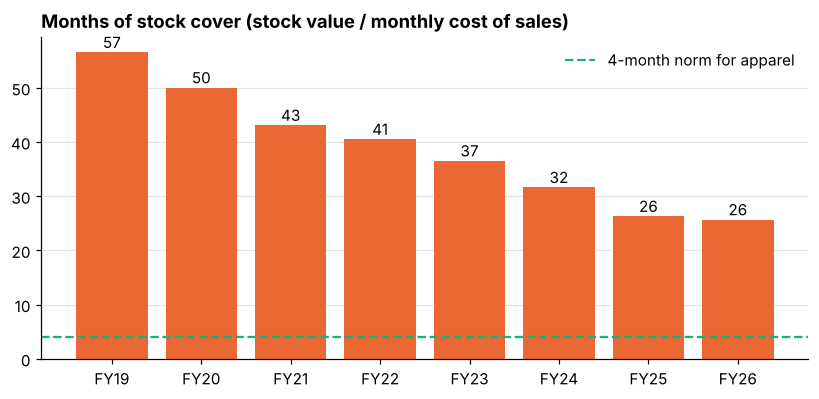

In [4]:
labels = [f"FY{str(y)[2:]}" for y in years]
plt.figure(figsize=(9, 3.8))
plt.bar(labels, year_end["months_of_cover"], color=ORANGE)
plt.axhline(4, color=GREEN, ls="--", label="4-month norm for apparel")
for i, v in enumerate(year_end["months_of_cover"]):
    plt.text(i, v + 0.8, f"{v:.0f}", ha="center")
plt.title("Months of stock cover (stock value / monthly cost of sales)")
plt.legend()
save("03_stock_cover")
plt.show()

**26 months of stock** at the end of FY26. Getting to 12 months would free:

In [5]:
monthly_cogs = cogs[2026] / 12
release = end["closing_stock_value_EGP"].sum() - 12 * monthly_cogs
print("Cash released:", millions(release))
print("Carrying cost saved at 15%/yr:", millions(release * 0.15))

Cash released: 203.6M
Carrying cost saved at 15%/yr: 30.5M


## 2. Transfers to branches

In [6]:
transfers = read("inventory_transfers.csv", dates=["transfer_date"])
items = read("inventory_transfer_items.csv")
moved = items.merge(transfers, on="transfer_id")
moved["FY"] = fiscal_year(moved["transfer_date"])
units_moved = moved[moved["FY"].isin(years)].groupby("FY")["quantity_units"].sum()

pd.DataFrame({"units_transferred": units_moved, "units_sold": units_sold, "ratio": (units_moved / units_sold).round(2)})

,units_transferred,units_sold,ratio
FY,,,
2019,1494946,253025,5.91
2020,1574346,289688,5.43
2021,1596820,325375,4.91
2022,1583919,375763,4.22
2023,1578945,436420,3.62
2024,1596263,500525,3.19
2025,1644602,567644,2.90
2026,1517691,620701,2.45


2.4x more units are moved to branches than are sold. Either goods come back, or transfers are double counted.

## 3. Purchase orders

In [7]:
po = read("purchase_orders.csv", dates=["po_date"])
po_items = read("purchase_order_items.csv", dates=["delivery_date"])
p = po_items.merge(po, on="po_id")
p["FY"] = fiscal_year(p["po_date"])
p["lead_days"] = (p["delivery_date"] - p["po_date"]).dt.days

bought = p[p["FY"].isin(years)].groupby("FY").agg(po_value=("line_cost_EGP", "sum"), po_units=("quantity", "sum"))
bought["cost_of_sales"] = cogs
bought["units_sold"] = units_sold
bought["value_ratio"] = bought["po_value"] / bought["cost_of_sales"]
bought["unit_ratio"] = bought["po_units"] / bought["units_sold"]
bought.round(1)

,po_value,po_units,cost_of_sales,units_sold,value_ratio,unit_ratio
FY,,,,,,
2019,1.283965e+09,40796083,11807767.7,253025,108.7,161.2
2020,1.502669e+09,42185241,15163786.7,289688,99.1,145.6
2021,1.672942e+09,42683780,19103806.6,325375,87.6,131.2
2022,2.168781e+09,42769577,28653932.9,375763,75.7,113.8
2023,3.006037e+09,42130702,45758206.3,436420,65.7,96.5
2024,4.630683e+09,43125833,80608721.1,500525,57.4,86.2
2025,6.457249e+09,42074944,130311339.8,567644,49.6,74.1
2026,8.105246e+09,41989793,178315606.4,620701,45.5,67.6


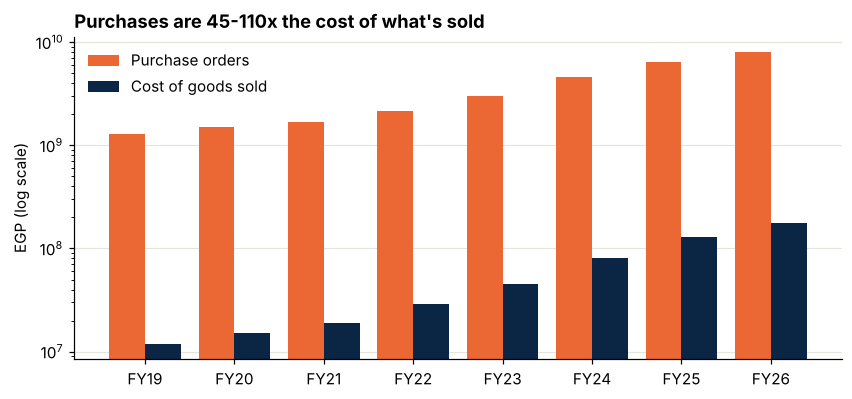

In [8]:
x = np.arange(len(years))
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, bought["po_value"], 0.4, color=ORANGE, label="Purchase orders")
plt.bar(x + 0.2, bought["cost_of_sales"], 0.4, color=NAVY, label="Cost of goods sold")
plt.yscale("log")
plt.xticks(x, labels)
plt.ylabel("EGP (log scale)")
plt.title("Purchases are 45-110x the cost of what's sold")
plt.legend()
save("03_purchases_vs_sales")
plt.show()

In [9]:
suppliers = p.groupby("supplier_id").agg(spend=("line_cost_EGP", "sum"), avg_lead_days=("lead_days", "mean"),
                                         partial=("po_status", lambda s: (s == "Partial receipt").mean()))
print(f"Average lead time per supplier: {suppliers['avg_lead_days'].min():.1f} to {suppliers['avg_lead_days'].max():.1f} days")
print(f"Partial receipts per supplier: {suppliers['partial'].min():.0%} to {suppliers['partial'].max():.0%}")
print(f"Top 5 suppliers' share of spend: {suppliers['spend'].nlargest(5).sum() / suppliers['spend'].sum():.0%}")

Average lead time per supplier: 28.3 to 29.4 days
Partial receipts per supplier: 29% to 36%
Top 5 suppliers' share of spend: 11%


Every supplier looks the same, so a supplier ranking would just rank noise.

## 4. Imports

In [10]:
imports = read("import_shipments.csv").merge(read("import_partners.csv"), on="import_partner_id")
cv = imports["customs_value_USD"].sum()
print(f"Customs value: USD {cv / 1e6:.0f}M | freight {imports['freight_USD'].sum() / cv:.1%} | duties {imports['duty_and_tax_USD'].sum() / cv:.1%}")
imports.groupby("country")["customs_value_USD"].sum().sort_values(ascending=False).map(millions)

Customs value: USD 450M | freight 5.7% | duties 10.0%


country
China       121.3M
Pakistan    110.1M
Türkiye      81.0M
India        56.8M
Vietnam      55.8M
Italy        25.2M
Name: customs_value_USD, dtype: str

Landed cost is about 16% above supplier price (10% duties + 6% freight).

**Summary:** stock covers ~26 months; transfers and purchases are on a different scale from sales and need reconciling.